In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#dataset load krwane mai help karegi
from datasets import load_dataset

Load the dair-ai/emotion dataset from Hugging Face. https://huggingface.co/datasets/dair-ai/emotion



In [2]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text      = emotion_dataset['train']['text']
train_label    = emotion_dataset["train"]["label"]
test_text      = emotion_dataset["test"]["text"]
test_label     = emotion_dataset["test"]["label"]

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [3]:
print(train_text)
print(train_label)

Column(['i didnt feel humiliated', 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake', 'im grabbing a minute to post i feel greedy wrong', 'i am ever feeling nostalgic about the fireplace i will know that it is still on the property', 'i am feeling grouchy', ...])
Column([0, 0, 3, 2, 3, ...])


In [4]:
label_names = emotion_dataset["train"].features["label"].names
print(label_names)

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


In [5]:
for i in train_label:
  print(label_names[i])

Streaming output truncated to the last 5000 lines.
sadness
sadness
anger
fear
love
joy
anger
sadness
sadness
joy
fear
joy
fear
love
love
anger
anger
sadness
fear
sadness
sadness
surprise
love
joy
joy
love
sadness
joy
joy
fear
sadness
anger
anger
sadness
love
fear
fear
anger
anger
joy
sadness
sadness
joy
joy
fear
sadness
joy
love
fear
anger
sadness
joy
anger
surprise
fear
joy
joy
love
fear
sadness
joy
anger
fear
anger
sadness
sadness
sadness
anger
sadness
fear
joy
anger
anger
sadness
fear
joy
anger
fear
sadness
joy
fear
joy
love
anger
fear
fear
fear
fear
joy
anger
anger
sadness
joy
sadness
joy
sadness
sadness
joy
sadness
fear
fear
joy
sadness
joy
sadness
joy
fear
anger
sadness
joy
anger
joy
joy
sadness
joy
joy
anger
anger
joy
joy
joy
sadness
joy
joy
joy
anger
anger
joy
love
joy
love
joy
joy
joy
sadness
joy
sadness
surprise
sadness
anger
anger
anger
fear
fear
joy
fear
fear
joy
anger
joy
joy
joy
love
joy
fear
sadness
sadness
surprise
sadness
sadness
anger
joy
love
fear
joy
anger
joy
surpr

In [6]:
df_train = pd.DataFrame(
    {
        "text": train_text,
        "label" : [label_names[i] for i in train_label]
    }
)

In [7]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [8]:
df_test = pd.DataFrame(
    {
        "text": test_text,
        "label" : [label_names[i] for i in test_label]
    }
)

In [9]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


**(EDA)**

<Axes: xlabel='label', ylabel='count'>

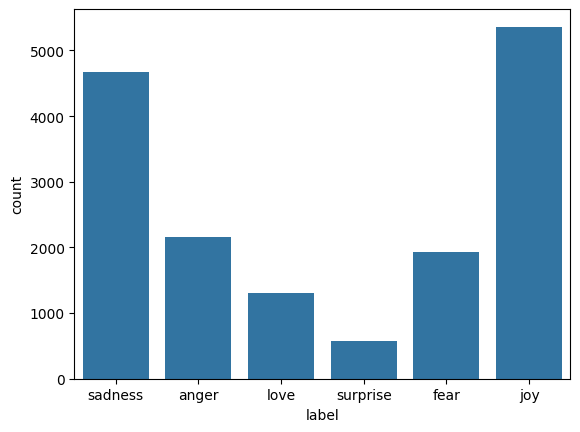

In [10]:
sns.countplot(x="label", data=df_train)

In [11]:
df_train["label"].value_counts()

,count
label,
joy,5362
sadness,4666
anger,2159
fear,1937
love,1304
surprise,572


**DATA PREPROCESSING - USING NLP**

In [12]:
from keras.src.legacy.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
max_word = 10000

tokenizer = Tokenizer(num_words=max_word,oov_token ="<unk>")
tokenizer.fit_on_texts(df_train["text"])


train_sequence = tokenizer.texts_to_sequences(df_train["text"])
test_sequence = tokenizer.texts_to_sequences(df_test["text"])

In [13]:
padded_train_sequence = pad_sequences(train_sequence,maxlen=50,padding="post",truncating="post")
padded_test_sequence = pad_sequences(test_sequence,maxlen=50,padding="post",truncating="post")

In [14]:
train_labels = np.array(train_label)
test_labels = np.array(test_label)

In [15]:
train_labels

array([0, 0, 3, ..., 1, 3, 0])

In [16]:
num_classes = len(np.unique(train_labels))
print(f"Vocabulary size: {len(tokenizer.word_index)}")
num_classes


Vocabulary size: 15213


6

**Balance class weight**

In [17]:
from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight(class_weight="balanced",classes=np.unique(train_labels),
                                     y=train_label)
class_weights=class_weight_dict = dict(enumerate(class_weights))

In [18]:
from keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor="val_loss",
                               patience=3,restore_best_weights=True)

**Plain Foundation Models**

**RNN MODELS**

In [19]:
from keras.models import Sequential
from keras.layers import Embedding,Dense,SimpleRNN,Dropout,LSTM,GRU
from keras import callbacks
rnn_model = Sequential([
    Embedding(input_dim=max_word, output_dim=64),
    SimpleRNN(64),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")
])

rnn_model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

early_stopping = EarlyStopping(monitor="val_loss", patience=5,
                               restore_best_weights=True)

rnn_model.fit(padded_train_sequence, train_labels,
              validation_split=0.2,
              epochs=20, batch_size=32,
              callbacks=[early_stopping])

rnn_loss,rnn_accuracy = rnn_model.evaluate(padded_test_sequence,test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")


Epoch 1/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.3260 - loss: 1.5974 - val_accuracy: 0.3256 - val_loss: 1.5831
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.4063 - loss: 1.5087 - val_accuracy: 0.4741 - val_loss: 1.4509
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.5764 - loss: 1.2122 - val_accuracy: 0.4847 - val_loss: 1.4102
Epoch 4/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.7051 - loss: 0.8744 - val_accuracy: 0.5325 - val_loss: 1.3667
Epoch 5/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.7970 - loss: 0.6174 - val_accuracy: 0.5219 - val_loss: 1.5297
Epoch 6/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8613 - loss: 0.4280 - val_accuracy: 0.5100 - val_loss: 1.6052
Epoch 7/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9012 - loss: 0.3125 - val_accuracy: 0.5372 - val_loss: 1.6619
Epoch 8/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9332 - loss: 0.2151 - val_ac

**LSTM MODELS**

In [20]:
lstm_model = Sequential([
    Embedding(input_dim=max_word, output_dim=64),
    LSTM(64),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")
])

lstm_model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

early_stopping = EarlyStopping(monitor="val_loss", patience=5,
                               restore_best_weights=True)

lstm_model.fit(padded_train_sequence, train_labels,
              validation_split=0.2,
              epochs=20, batch_size=32,
              callbacks=[early_stopping])


lstm_loss,lstm_accuracy = lstm_model.evaluate(padded_test_sequence,test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")


Epoch 1/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 16s 36ms/step - accuracy: 0.3262 - loss: 1.5908 - val_accuracy: 0.3262 - val_loss: 1.5790
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 22s 39ms/step - accuracy: 0.3319 - loss: 1.5802 - val_accuracy: 0.2997 - val_loss: 1.5770
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 20s 49ms/step - accuracy: 0.3338 - loss: 1.5793 - val_accuracy: 0.3259 - val_loss: 1.5812
Epoch 4/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.3354 - loss: 1.5664 - val_accuracy: 0.3422 - val_loss: 1.5425
Epoch 5/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 18s 46ms/step - accuracy: 0.3320 - loss: 1.5266 - val_accuracy: 0.3091 - val_loss: 1.5404
Epoch 6/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 23s 51ms/step - accuracy: 0.3362 - loss: 1.5002 - val_accuracy: 0.3506 - val_loss: 1.4746
Epoch 7/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 33s 31ms/step - accuracy: 0.3634 - loss: 1.5117 - val_accuracy: 0.3519 - val_loss: 1.5233
Epoch 8/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 22s 36ms/step - accuracy: 0.3499 - loss: 1.5524 - 

**GRU MODELS**

In [21]:
gru_model = Sequential([
    Embedding(input_dim=max_word, output_dim=64),
    GRU(64),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")
])

gru_model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

early_stopping = EarlyStopping(monitor="val_loss", patience=5,
                               restore_best_weights=True)

gru_model.fit(padded_train_sequence, train_labels,
              validation_split=0.2,
              epochs=20, batch_size=32,
              callbacks=[early_stopping])


gru_loss,gru_accuracy = gru_model.evaluate(padded_test_sequence,test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.3261 - loss: 1.5886 - val_accuracy: 0.3266 - val_loss: 1.5742
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.3344 - loss: 1.5812 - val_accuracy: 0.3262 - val_loss: 1.5812
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.4384 - loss: 1.3691 - val_accuracy: 0.6938 - val_loss: 0.7770
Epoch 4/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 22s 39ms/step - accuracy: 0.7886 - loss: 0.6062 - val_accuracy: 0.8706 - val_loss: 0.4223
Epoch 5/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 24s 60ms/step - accuracy: 0.9087 - loss: 0.2881 - val_accuracy: 0.9106 - val_loss: 0.2598
Epoch 6/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - accuracy: 0.9457 - loss: 0.1624 - val_accuracy: 0.9150 - val_loss: 0.2389
Epoch 7/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.9570 - loss: 0.1187 - val_accuracy: 0.9153 - val_loss: 0.2628
Epoch 8/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.9646 - loss: 0.0954 - 

**Ranking & Selection**

In [22]:
result_df = pd.DataFrame({
    "Model": ["RNN", "LSTM", "GRU"],
    "Test Loss": [rnn_loss, lstm_loss, gru_loss],
    " Test Accuracy": [rnn_accuracy, lstm_accuracy, gru_accuracy]
})

result_df

,Model,Test Loss,Test Accuracy
0,RNN,1.334486,0.5390
1,LSTM,1.451441,0.3610
2,GRU,0.243813,0.9205


** Advanced Bidirectional GRU **

In [24]:
from keras.layers import Bidirectional
BiGRU = Sequential([
    Embedding(input_dim=max_word, output_dim=300,input_length=50),
    Bidirectional(GRU(64)),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")


    ])
BiGRU.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

early_stopping = EarlyStopping(monitor="val_loss", patience=5,
                               restore_best_weights=True)

BiGRU.fit(padded_train_sequence, train_labels,
              validation_split=0.2,
              epochs=20, batch_size=32,
              callbacks=[early_stopping])


BiGRU_loss,BiGRU_accuracy = BiGRU.evaluate(padded_test_sequence,test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

Epoch 1/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 55s 129ms/step - accuracy: 0.5805 - loss: 1.1193 - val_accuracy: 0.8228 - val_loss: 0.5026
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 80s 125ms/step - accuracy: 0.8831 - loss: 0.3311 - val_accuracy: 0.9044 - val_loss: 0.2698
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 109s 193ms/step - accuracy: 0.9495 - loss: 0.1382 - val_accuracy: 0.9144 - val_loss: 0.2386
Epoch 4/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 57s 130ms/step - accuracy: 0.9672 - loss: 0.0810 - val_accuracy: 0.9159 - val_loss: 0.2738
Epoch 5/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 50s 125ms/step - accuracy: 0.9797 - loss: 0.0578 - val_accuracy: 0.9147 - val_loss: 0.2797
Epoch 6/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 105s 184ms/step - accuracy: 0.9861 - loss: 0.0387 - val_accuracy: 0.9081 - val_loss: 0.3394
Epoch 7/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 66s 164ms/step - accuracy: 0.9898 - loss: 0.0279 - val_accuracy: 0.9103 - val_loss: 0.3564
Epoch 8/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 54s 136ms/step - accuracy: 0.9929 - loss:

**Final model Confusion Metrices**

63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step


<Axes: >

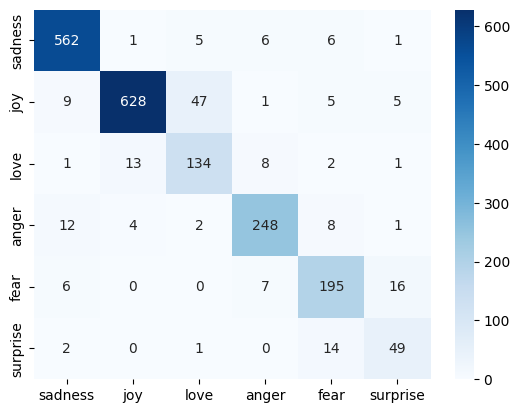

In [29]:
from sklearn.metrics import confusion_matrix
BiGRU_prediction = BiGRU.predict(padded_test_sequence)
BiGRU_prediction = np.argmax(BiGRU_prediction, axis=1)
sns.heatmap(confusion_matrix(test_labels, BiGRU_prediction),
            annot=True,fmt="d",cmap="Blues",xticklabels=label_names,yticklabels = label_names)

**Final Predictions**

In [30]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sampl_padded_sequences = pad_sequences(sample_sequences, maxlen=50,
                                       padding="post", truncating="post")


sample_predictions = BiGRU.predict(sampl_padded_sequences)
sample_predictions = np.argmax(sample_predictions, axis=1)

for i in range(len(sample_texts)):
    print(f"Text: {sample_texts[i]}")
    print(f"Predicted Emotion: {label_names[sample_predictions[i]]}\n")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: joy

Text: I feel so alone and hopeless today.
Predicted Emotion: sadness

Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger

Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear

Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise



**Final Save Model & Tokenizer**

In [32]:
import os
import pickle

model_dir = "Artfacts"
os.makedirs(model_dir,exist_ok=True)

# Save BiGRU Model
BiGRU.save(os.path.join(model_dir,"BiGRU_model.keras"))


# save Tokenizer model
with open(os.path.join(model_dir,"tokenizer.pkl"),"wb") as file:
  pickle.dump(tokenizer,file)
